In [12]:
import sys
print(sys.executable)

/Users/vaishnavipoojary/CliO-customer-feedback-analytics/.venv/bin/python


In [13]:

from pathlib import Path
import gzip
import json
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().parent
RAW_DIR = PROJECT_ROOT / "data" / "raw"

review_path = RAW_DIR / "Cell_Phones_and_Accessories.jsonl.gz"
metadata_path = RAW_DIR / "meta_Cell_Phones_and_Accessories.jsonl.gz"

print("Project directory:", PROJECT_ROOT)
print("Review file exists:", review_path.exists())
print("Metadata file exists:", metadata_path.exists())


Project directory: /Users/vaishnavipoojary/CliO-customer-feedback-analytics
Review file exists: True
Metadata file exists: True


In [14]:

def read_jsonl_sample(path, n=5000):
    records = []

    with gzip.open(path, "rt", encoding="utf-8") as file:
        for line in file:
            records.append(json.loads(line))
            if len(records) >= n:
                break

    return pd.DataFrame(records)


reviews_sample = read_jsonl_sample(review_path, n=5000)
products_sample = read_jsonl_sample(metadata_path, n=5000)

print("Reviews sample shape:", reviews_sample.shape)
print("Products sample shape:", products_sample.shape)


Reviews sample shape: (5000, 10)
Products sample shape: (5000, 16)


In [15]:

display(reviews_sample.head())
display(products_sample.head())


,rating,title,text,images,asin,parent_asin,user_id,timestamp,helpful_vote,verified_purchase
0,4.0,No white background! It’s clear!,I bought this bc I thought it had the nice whi...,[{'small_image_url': 'https://images-na.ssl-im...,B08L6L3X1S,B08L6L3X1S,AFKZENTNBQ7A7V7UXW5JJI6UGRYQ,1612044451196,0,True
1,5.0,Awesome! Great price! Works well!,Perfect. How pissed am I that I recently paid ...,[],B079BPGF6C,B079BPGF6C,AFKZENTNBQ7A7V7UXW5JJI6UGRYQ,1534443517349,2,True
2,5.0,Worked but took an hour to install,Overall very happy with the end result. If you...,[{'small_image_url': 'https://m.media-amazon.c...,B088DR7Z5B,B0BBGGC8F2,AGCI7FAH4GL5FI65HYLKWTMFZ2CQ,1629235304798,3,True
3,4.0,Decent,Lasted about 9 months then the lock button bro...,[{'small_image_url': 'https://images-na.ssl-im...,B07XRDHDNQ,B07XRDHDNQ,AGCI7FAH4GL5FI65HYLKWTMFZ2CQ,1590470082910,0,True
4,5.0,LOVE IT!,LOVE THIS CASE! Works better than my expensive...,[],B00A8ZDL9Y,B00A8ZDL9Y,AGCI7FAH4GL5FI65HYLKWTMFZ2CQ,1408994588000,0,True


,main_category,title,average_rating,rating_number,features,description,price,images,videos,store,categories,details,parent_asin,bought_together,subtitle,author
0,Cell Phones & Accessories,ARAREE Slim Diary Cell Phone Case for Samsung ...,3.8,5,"[Genuine Cow leather with 6 different colors, ...","[JUST LOOK, You can tell the difference. Make ...",NaN,[{'thumb': 'https://m.media-amazon.com/images/...,[],araree,"[Cell Phones & Accessories, Cases, Holsters & ...",{'Product Dimensions': '3.35 x 0.59 x 6.18 inc...,B013SK1JTY,None,NaN,NaN
1,Cell Phones & Accessories,Bastmei for OnePlus 7T Case Extremely Light Ul...,4.4,177,[Ultra-thin & Ultra-light: The ultra slim fit ...,[],11.98,[{'thumb': 'https://m.media-amazon.com/images/...,[],Bastmei,"[Cell Phones & Accessories, Cases, Holsters & ...",{'Package Dimensions': '7.6 x 4.29 x 0.75 inch...,B07ZPSG8P5,None,NaN,NaN
2,Cell Phones & Accessories,Wireless Fones Branded New Iphone 5C/LITE Hot ...,4.0,2,[],[],NaN,[{'thumb': 'https://m.media-amazon.com/images/...,[],WIRELESS FONES,"[Cell Phones & Accessories, iPhone Accessories]","{'Item model number': 'Apple Iphone 5C', 'Othe...",B00GKR3L12,None,NaN,NaN
3,Cell Phones & Accessories,"iPhone 6 Plus + Case, DandyCase Perfect PATTER...",4.0,15,"[Slim-Fit design for the iPhone 6 Plus (5.5"" s...",[Case does not need to be removed for charging...,NaN,[{'thumb': 'https://m.media-amazon.com/images/...,[],DandyCase,"[Cell Phones & Accessories, iPhone Accessories]",{'Product Dimensions': '5.43 x 0.28 x 2.64 inc...,B00PB8U8BW,None,NaN,NaN
4,Cell Phones & Accessories,"Case for Galaxy S6/S6 Edge, Thin Translucent V...",4.0,1,[],[],NaN,[{'thumb': 'https://m.media-amazon.com/images/...,[],7Pite,"[Cell Phones & Accessories, Cases, Holsters & ...",{'Package Dimensions': '8.31 x 3.74 x 0.55 inc...,B07D3RHSRV,None,NaN,NaN


In [16]:

print("Review columns:")
print(reviews_sample.columns.tolist())

print("\nProduct metadata columns:")
print(products_sample.columns.tolist())


Review columns:
['rating', 'title', 'text', 'images', 'asin', 'parent_asin', 'user_id', 'timestamp', 'helpful_vote', 'verified_purchase']

Product metadata columns:
['main_category', 'title', 'average_rating', 'rating_number', 'features', 'description', 'price', 'images', 'videos', 'store', 'categories', 'details', 'parent_asin', 'bought_together', 'subtitle', 'author']


In [17]:

# Missing values in the review sample
review_missing = reviews_sample.isnull().sum().sort_values(ascending=False)

print("Missing values in review sample:")
display(review_missing.to_frame(name="missing_count"))

# Missing values in the product metadata sample
product_missing = products_sample.isnull().sum().sort_values(ascending=False)

print("Missing values in product metadata sample:")
display(product_missing.to_frame(name="missing_count"))


Missing values in review sample:


,missing_count
rating,0
title,0
text,0
images,0
asin,0
parent_asin,0
user_id,0
timestamp,0
helpful_vote,0
verified_purchase,0


Missing values in product metadata sample:


,missing_count
bought_together,5000
subtitle,5000
author,5000
price,3165
store,45
main_category,8
title,0
average_rating,0
rating_number,0
features,0


,review_count
rating,
1.0,458
2.0,232
3.0,383
4.0,669
5.0,3258


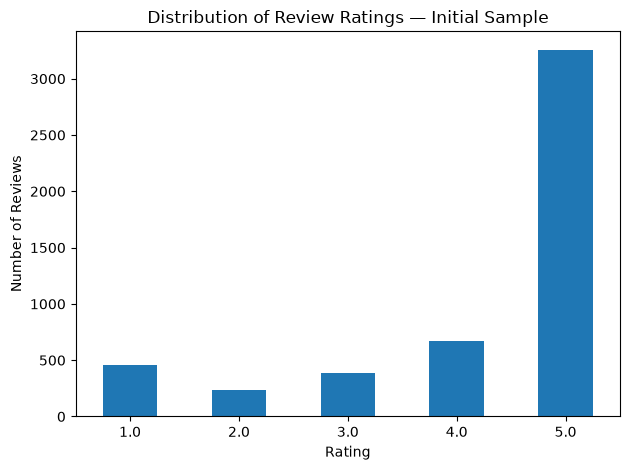

In [18]:

rating_counts = reviews_sample["rating"].value_counts().sort_index()

display(rating_counts.to_frame(name="review_count"))

rating_counts.plot(kind="bar", rot=0)
plt.title("Distribution of Review Ratings — Initial Sample")
plt.xlabel("Rating")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()


Review length analysis

In [19]:

# Measure review text length
reviews_sample["text"] = reviews_sample["text"].fillna("")
reviews_sample["title"] = reviews_sample["title"].fillna("")

reviews_sample["review_length"] = reviews_sample["text"].astype(str).str.len()
reviews_sample["word_count"] = reviews_sample["text"].astype(str).str.split().str.len()

print("Empty review texts:", reviews_sample["text"].str.strip().eq("").sum())
print("Empty review titles:", reviews_sample["title"].str.strip().eq("").sum())

display(
    reviews_sample[["review_length", "word_count"]]
    .describe()
    .round(2)
)


Empty review texts: 1
Empty review titles: 0


,review_length,word_count
count,5000.00,5000.00
mean,287.84,53.69
std,683.84,120.70
min,1.00,0.00
25%,49.00,9.00
50%,123.00,23.50
75%,278.00,53.00
max,10673.00,1811.00


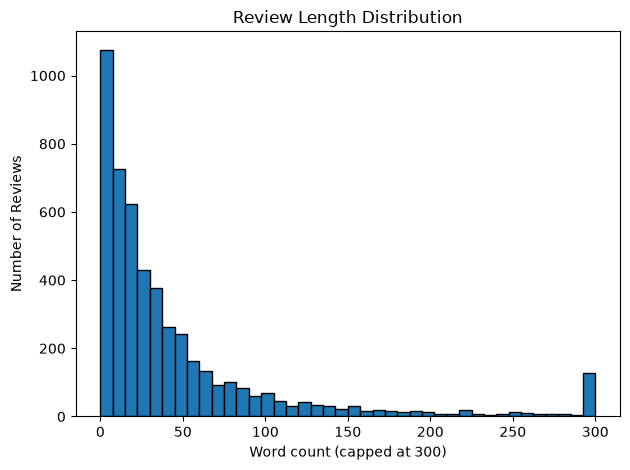

In [20]:

reviews_sample["word_count"].clip(upper=300).plot(
    kind="hist", bins=40, edgecolor="black"
)

plt.title("Review Length Distribution")
plt.xlabel("Word count (capped at 300)")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()


In [22]:

# 1. Exact duplicates based on scalar review fields
scalar_columns = [
    "rating",
    "title",
    "text",
    "asin",
    "parent_asin",
    "user_id",
    "timestamp",
    "helpful_vote",
    "verified_purchase",
]

exact_duplicates = reviews_sample.duplicated(
    subset=scalar_columns
).sum()

# 2. Duplicate review text
duplicate_texts = (
    reviews_sample["text"]
    .fillna("")
    .astype(str)
    .str.strip()
    .duplicated()
    .sum()
)

# 3. Duplicate product-review combinations
duplicate_product_reviews = reviews_sample.duplicated(
    subset=["parent_asin", "user_id", "text"]
).sum()

print("Duplicate rows (excluding list-valued images):", exact_duplicates)
print("Duplicate review texts:", duplicate_texts)
print("Duplicate product-review combinations:", duplicate_product_reviews)


Duplicate rows (excluding list-valued images): 0
Duplicate review texts: 198
Duplicate product-review combinations: 1


In [23]:

# Check product identifier overlap in our initial samples

review_ids = set(reviews_sample["parent_asin"].dropna())
product_ids = set(products_sample["parent_asin"].dropna())

matched_ids = review_ids.intersection(product_ids)

print("Unique review product IDs:", len(review_ids))
print("Unique metadata product IDs:", len(product_ids))
print("Matching product IDs:", len(matched_ids))
print("Review IDs with metadata match:", len(matched_ids) / len(review_ids) * 100 if review_ids else 0, "%")


Unique review product IDs: 4469
Unique metadata product IDs: 5000
Matching product IDs: 48
Review IDs with metadata match: 1.074065786529425 %


In [24]:

# Select 100 reviews for a matching test
test_reviews = reviews_sample.head(100).copy()

target_ids = set(test_reviews["parent_asin"].dropna().astype(str))
matched_products = {}

# Scan metadata until all target IDs are found or the file ends
with gzip.open(metadata_path, "rt", encoding="utf-8") as file:
    for line in file:
        product = json.loads(line)
        product_id = product.get("parent_asin")

        if product_id in target_ids:
            matched_products[product_id] = product

        if len(matched_products) == len(target_ids):
            break

print("Review IDs tested:", len(target_ids))
print("Matching metadata records:", len(matched_products))
print(
    "Match rate:",
    round(len(matched_products) / len(target_ids) * 100, 2),
    "%"
)


Review IDs tested: 100
Matching metadata records: 100
Match rate: 100.0 %


In [25]:

# Inspect matched product titles
for product in list(matched_products.values())[:30]:
    print(product.get("title", "No title"))


MOSNOVO Astronaut Planet Pattern Designed for iPhone Xs Case/Designed for iPhone X Case,Clear Case with Design,TPU Bumper with Protective Hard Case Cover
SHENMZ LG V20 Battery,6800mAh (More Than 2X Extra Battery Power) Replacement LG V20 Extended Battery BL-44E1F with Black TPU Case for LG H910 H918 VS995 LS997 Phone | LG V20 Battery Case
iSaddle CH368 Ulimate Car Rearview Mirror Mount Kit Dash Cam Holder for Yi Smart Dash Cam/Apeman/Z-Edge/BlackBox/Spy Tec/Transcend/DOD/Papago/Vicovation/HP Bicycle Handlebar Holder
KEZiHOME Case for Pixel 4a [Not Fit Google Pixel 4a 5G], Genuine Leather [RFID Blocking] Google Pixel 4a Wallet Case Credit Card Slot Flip Folio Magnetic Stand Case for Google Pixel 4a (Khaki/Brown)
Tribit Bluetooth Headset, Wireless Headset with Microphone Qualcomm CVC 8.0 AI Noise Canceling for Trucker Office, 50H Talk Time Mute Button Headset with Adapter for Computer Cell Phones, CallElite81
LUVVITT iPhone 6s Plus Case, [Ultra Armor] Shock Absorbing Case Best Heavy Duty

In [48]:

import re

EXCLUDE_TERMS = re.compile(
    r"\b(case|cover|screen protector|protector|charger|"
    r"charging pad|battery|headset|earbuds|stand|mount|"
    r"holder|cable|adapter|stylus|skin|replacement parts)\b",
    flags=re.IGNORECASE
)

PHONE_TERMS = re.compile(
    r"\b(smartphone|cell phone|mobile phone|"
    r"iphone|google pixel|samsung galaxy [a-z]?\d|"
    r"motorola moto [a-z]?\d|oneplus|xiaomi|"
    r"nokia [a-z0-9]+|blu view)\b",
    flags=re.IGNORECASE
)

def is_candidate_smartphone(title):
    title = str(title)

    if EXCLUDE_TERMS.search(title):
        return False

    return bool(PHONE_TERMS.search(title))


sample_titles = [
    product.get("title", "")
    for product in matched_products.values()
]

for title in sample_titles:
    if is_candidate_smartphone(title):
        print("CANDIDATE:", title)


CANDIDATE: TracFone Blu View 2 4G LTE Prepaid Smartphone (Locked) - Black - 32GB - Sim Card Included - CDMA
CANDIDATE: for Apple iPhone 4 4G Touch Screen Digitizer and LCD Assembly - White (AT&T GSM Model)
CANDIDATE: Nokia Lumia 635 8GB Unlocked GSM 4G LTE Windows 8.1 Quad-Core Smartphone - Black
CANDIDATE: ZTE Blade A3 Lite 5.0" 18:9 Display, 8MP Camera Quad-Core Android 9.0 Go (LTE USA Latin Caribbean) 4G LTE GSM Unlocked Smartphone - International Version (Black, 32GB)


In [52]:

EXCLUDE_TERMS = re.compile(
    r"\b(case|cover|screen protector|protector|charger|"
    r"charging pad|battery|headset|earbuds|stand|mount|"
    r"holder|cable|adapter|stylus|skin|replacement parts|"
    r"digitizer|lcd assembly|replacement screen|screen assembly)\b",
    flags=re.IGNORECASE
)


PHONE_TERMS = re.compile(
    r"\b("
    r"smartphone|cell phone|mobile phone|"
    r"iphone|google pixel|pixel [0-9]|"
    r"samsung galaxy|galaxy [a-z]?\d|"
    r"motorola moto|motorola edge|motorola razr|"
    r"oneplus|xiaomi|redmi|poco|"
    r"nokia|oppo|vivo|realme|huawei|honor|"
    r"alcatel|sony xperia|tecno|infinix|"
    r"nothing phone"
    r")\b",
    flags=re.IGNORECASE
)


def is_candidate_smartphone(title):
    title = str(title)

    if EXCLUDE_TERMS.search(title):
        return False

    return bool(PHONE_TERMS.search(title))


In [53]:

for title in sample_titles:
    if is_candidate_smartphone(title):
        print("CANDIDATE:", title)


CANDIDATE: TracFone Blu View 2 4G LTE Prepaid Smartphone (Locked) - Black - 32GB - Sim Card Included - CDMA
CANDIDATE: Nokia Lumia 635 8GB Unlocked GSM 4G LTE Windows 8.1 Quad-Core Smartphone - Black
CANDIDATE: ZTE Blade A3 Lite 5.0" 18:9 Display, 8MP Camera Quad-Core Android 9.0 Go (LTE USA Latin Caribbean) 4G LTE GSM Unlocked Smartphone - International Version (Black, 32GB)


In [54]:

# Read 500 product metadata records for a preliminary filter check
metadata_sample_500 = read_jsonl_sample(metadata_path, n=500)

metadata_sample_500["is_candidate_smartphone"] = (
    metadata_sample_500["title"]
    .fillna("")
    .apply(is_candidate_smartphone)
)

print("Products inspected:", len(metadata_sample_500))
print(
    "Candidate smartphones:",
    metadata_sample_500["is_candidate_smartphone"].sum()
)

print("\nCandidate titles:")
display(
    metadata_sample_500.loc[
        metadata_sample_500["is_candidate_smartphone"],
        ["title"]
    ].head(30)
)


Products inspected: 500
Candidate smartphones: 20

Candidate titles:


,title
5,Rikki Knight 3D Chevron Peach on White with An...
24,Areziir Gapless Elegant Bands Compatible with ...
27,NINKI Sparkling Band Compatible Samsung Galaxy...
57,Generic Shimmery Replacement Front Screen Glas...
61,Lencca Kyma Vegan Leather Crossbody Smartphone...
63,Samsung Galaxy Note 5 N920T 64GB Unlocked GSM ...
64,"Alcatel 1C 2019 5003G 3G 5.0"" Quad-Core 8GB 1G..."
67,Puregear 60184PG Dualtek for Galaxy S4 - 1 Pac...
90,Sankel Leather Strap Compatible for Samsung Ga...
148,Kitway Band Compatible for Samsung Galaxy Watc...


In [55]:

EXCLUDE_TERMS = re.compile(
    r"\b(case|cover|screen protector|protector|charger|"
    r"charging pad|battery|headset|earbuds|stand|mount|"
    r"holder|cable|adapter|stylus|skin|replacement parts|"
    r"digitizer|lcd assembly|replacement screen|screen assembly|"
    r"front screen glass|crossbody|phone bag|waterproof bag|"
    r"usb phone fan|fan for phone|phone fan|"
    r"phone wallet|phone pouch|phone grip|phone strap|"
    r"tripod|selfie stick|car mount)\b",
    flags=re.IGNORECASE
)

def is_candidate_smartphone(title):
    title = str(title)

    if EXCLUDE_TERMS.search(title):
        return False

    return bool(PHONE_TERMS.search(title))


In [56]:

metadata_sample_500["is_candidate_smartphone"] = (
    metadata_sample_500["title"]
    .fillna("")
    .apply(is_candidate_smartphone)
)

print(
    "Candidate smartphones:",
    metadata_sample_500["is_candidate_smartphone"].sum()
)

display(
    metadata_sample_500.loc[
        metadata_sample_500["is_candidate_smartphone"],
        ["title"]
    ]
)


Candidate smartphones: 16


,title
5,Rikki Knight 3D Chevron Peach on White with An...
24,Areziir Gapless Elegant Bands Compatible with ...
27,NINKI Sparkling Band Compatible Samsung Galaxy...
63,Samsung Galaxy Note 5 N920T 64GB Unlocked GSM ...
64,"Alcatel 1C 2019 5003G 3G 5.0"" Quad-Core 8GB 1G..."
67,Puregear 60184PG Dualtek for Galaxy S4 - 1 Pac...
90,Sankel Leather Strap Compatible for Samsung Ga...
148,Kitway Band Compatible for Samsung Galaxy Watc...
206,MPERO Collection 5-Pack of Mirror Screen Prote...
254,"BLU Vivo XL4 6.2"" HD Display Smartphone 32Gb+3..."


In [57]:

candidates = metadata_sample_500.loc[
    metadata_sample_500["is_candidate_smartphone"],
    ["title"]
]

for i, title in enumerate(candidates["title"], start=1):
    print(f"{i}. {title}\n")


1. Rikki Knight 3D Chevron Peach on White with Anchor Flip Wallet iPhoneCase with Magnetic Flap for Apple iPhone 5c

2. Areziir Gapless Elegant Bands Compatible with Samsung Galaxy Watch 4/Watch 5 Band 40mm 44mm/Galaxy Watch 4 Classic 42mm 46mm/Galaxy Watch 5 Pro 45mm,Flower Silicone Pattern Replacement Strap Women Men

3. NINKI Sparkling Band Compatible Samsung Galaxy Watch 5/4 40mm 44mm/Classic 42mm 46mm/Active 2 Watch Bands Resin,（Sliver+Black Pink）20mm Stainless Steel Bracelet Band for Galaxy Watch 3 41mm/Watch 42mm

4. Samsung Galaxy Note 5 N920T 64GB Unlocked GSM - Black Sapphire

5. Alcatel 1C 2019 5003G 3G 5.0" Quad-Core 8GB 1GB Ram 5MP Android 8.1 Factory Unlocked Smartphone (Pink)

6. Puregear 60184PG Dualtek for Galaxy S4 - 1 Pack - Retail Packaging - Simply Pink

7. Sankel Leather Strap Compatible for Samsung Galaxy Watch4/Classic/Watch 3 41mm/Active/Active 2 Bands,Women 20mm Leather Strap Replacement Wristband for Galaxy Watch 4/Active 2/Gear Sport (Sand Pink)

8. Kitway B

In [58]:

# Review all candidates from the 500-product sample
candidate_titles = metadata_sample_500.loc[
    metadata_sample_500["is_candidate_smartphone"],
    "title"
].tolist()

for i, title in enumerate(candidate_titles, start=1):
    print(f"{i}. {title}\n")


1. Rikki Knight 3D Chevron Peach on White with Anchor Flip Wallet iPhoneCase with Magnetic Flap for Apple iPhone 5c

2. Areziir Gapless Elegant Bands Compatible with Samsung Galaxy Watch 4/Watch 5 Band 40mm 44mm/Galaxy Watch 4 Classic 42mm 46mm/Galaxy Watch 5 Pro 45mm,Flower Silicone Pattern Replacement Strap Women Men

3. NINKI Sparkling Band Compatible Samsung Galaxy Watch 5/4 40mm 44mm/Classic 42mm 46mm/Active 2 Watch Bands Resin,（Sliver+Black Pink）20mm Stainless Steel Bracelet Band for Galaxy Watch 3 41mm/Watch 42mm

4. Samsung Galaxy Note 5 N920T 64GB Unlocked GSM - Black Sapphire

5. Alcatel 1C 2019 5003G 3G 5.0" Quad-Core 8GB 1GB Ram 5MP Android 8.1 Factory Unlocked Smartphone (Pink)

6. Puregear 60184PG Dualtek for Galaxy S4 - 1 Pack - Retail Packaging - Simply Pink

7. Sankel Leather Strap Compatible for Samsung Galaxy Watch4/Classic/Watch 3 41mm/Active/Active 2 Bands,Women 20mm Leather Strap Replacement Wristband for Galaxy Watch 4/Active 2/Gear Sport (Sand Pink)

8. Kitway B

In [34]:

# Randomly inspect 30 products excluded by our filter
excluded_sample = metadata_sample_500.loc[
    ~metadata_sample_500["is_candidate_smartphone"],
    ["title"]
].sample(
    n=min(30, (~metadata_sample_500["is_candidate_smartphone"]).sum()),
    random_state=42
)

for i, title in enumerate(excluded_sample["title"], start=1):
    print(f"{i}. {title}\n")


1. Galaxy j3 2018/J3 Achieve/Express Prime 3/j3 Star/J3 V 3rd Gen 2018/j3 Orbit case,Skyfree Heavy Duty Dual Layer Bumper Protective Phone Case for Samsung Galaxy J3 2018,Lion and Lioness Lovers

2. GUAGUA Compatible with iPhone 12/12 Pro Case 6.1" Hybrid 3 in 1 Hard PC Soft TPU Heavy Duty Rugged Bumper Shockproof Full-Body Protective Phone Cover with Magnetic Ring Kickstand, Purple

3. Ronald Acuña Jr. Home Run Celebration Case Cover Compatible for iPhone iPhone (11) (12 Pro Max)

4. I-HONVA for Galaxy S10E Case Shockproof Dust/Drop Proof 3-Layer Full Body Protection [Without Screen Protector] Rugged Heavy Duty Durable Cover Case for Samsung Galaxy S10E,Purple/Green

5. Incipio BB-1022 Feather Case for BlackBerry Q10-1 Pack - Retail Packaging - Obsidian Black

6. MPERO Collection 5-Pack of Mirror Screen Protectors for Motorola Moto G (2nd Gen) 2014

7. iRonSmith (TM) Premium Real Anti Spy Privacy Tempered Glass Screen Protector For Samsung Galaxy S5 [Oleophobic Coating 0.3mm,2.5D Roun

In [59]:

import random

random.seed(42)
random_titles = []

with gzip.open(metadata_path, "rt", encoding="utf-8") as file:
    for line in file:
        product = json.loads(line)
        title = product.get("title", "")
        if title:
            random_titles.append(title)

        # Stop after collecting a manageable set for this first pass
        if len(random_titles) >= 5000:
            break

random_sample_titles = random.sample(
    random_titles,
    min(500, len(random_titles))
)

random_sample_df = pd.DataFrame({"title": random_sample_titles})
random_sample_df["candidate"] = random_sample_df["title"].apply(
    is_candidate_smartphone
)

print("Products inspected:", len(random_sample_df))
print("Candidate smartphones:", random_sample_df["candidate"].sum())

display(random_sample_df.loc[random_sample_df["candidate"], ["title"]])


Products inspected: 500
Candidate smartphones: 13


,title
15,Nokia 6500 Slide Black/silver Unlocked Cell Phone
41,Google Pixel 4 XL 64 GB Verizon (Just Black)
72,"Apple iPhone 14 Plus, 512GB, (PRODUCT) Red - U..."
119,ANCOOL Compatible with Samsung Galaxy Watch 42...
162,Asmyna MyJacket Wallet with Tray 561 for Samsu...
190,Gonezon Big Capacity 2 Layers Waterproof Cellp...
288,CJB Dust Plug / Earphone Jack Accessory Heart ...
289,Fit for Samsung Galaxy Watch Active 2 Watch Ba...
330,"Alcatel 1C 2019 5003G 3G 5.0"" Quad-Core 8GB 1G..."
346,Samsung Galaxy S20 FE 5G UW 128GB for Verizon ...


In [70]:

EXCLUDE_TERMS = re.compile(
    r"\b(case|cover|screen protector|protector|charger|"
    r"charging pad|battery|headset|earbuds|stand|mount|"
    r"holder|cable|adapter|stylus|skin|replacement parts|"
    r"digitizer|lcd assembly|replacement screen|screen assembly|"
    r"front screen glass|crossbody|phone bag|waterproof bag|"
    r"usb phone fan|phone fan|phone wallet|phone pouch|"
    r"phone grip|phone strap|phone lanyard|lanyard|"
    r"tripod|selfie stick|car mount|wallet|dust plug|"
    r"earphone jack accessory|screen glass|"
    r"watch|6500 slide|"
    r"smartwatch band|replacement strap|"
    r"cellphone bag|waterproof cellphone)\b",
    flags=re.IGNORECASE
)


def is_candidate_smartphone(title):
    title = str(title)

    # Exclude accessories first
    if EXCLUDE_TERMS.search(title):
        return False

    # Require a recognizable smartphone or phone model
    return bool(PHONE_TERMS.search(title))




In [71]:

random_sample_df["candidate_updated"] = (
    random_sample_df["title"].apply(is_candidate_smartphone)
)

print("Updated candidates:", random_sample_df["candidate_updated"].sum())

display(
    random_sample_df.loc[
        random_sample_df["candidate_updated"], ["title"]
    ]
)


Updated candidates: 5


,title
41,Google Pixel 4 XL 64 GB Verizon (Just Black)
72,"Apple iPhone 14 Plus, 512GB, (PRODUCT) Red - U..."
330,"Alcatel 1C 2019 5003G 3G 5.0"" Quad-Core 8GB 1G..."
346,Samsung Galaxy S20 FE 5G UW 128GB for Verizon ...
458,"Apple iPhone 6 64 GB AT&T, Space Gray"


In [74]:

print("Total titles checked:", len(random_sample_df))
print("Smartphone candidates:", random_sample_df["candidate_updated"].sum())
print(
    "Excluded titles:",
    (~random_sample_df["candidate_updated"]).sum()
)

display(
    random_sample_df.loc[
        ~random_sample_df["candidate_updated"], ["title"]
    ].sample(
        n=min(20, (~random_sample_df["candidate_updated"]).sum()),
        random_state=42
    )
)


Total titles checked: 500
Smartphone candidates: 5
Excluded titles: 495


,title
461,"S6 Edge Case, Galaxy S6 Edge Case, TILL Studde..."
75,FGA Compatible with iPhone 12 Case/iPhone 12 P...
312,"Moto G4 Plus Case, Cellularvilla [Slim Fit] [C..."
177,"for iPhone 12 Pro Case,Cool Space Psychedelic ..."
336,Fintie iPad 1 Case - Slim Lightweight PU Leath...
206,CMEKA Emboss Butterfly Wallet Case for Motorol...
157,Fonus Brand Two USB DC Cup Holder Cigarette Li...
56,Mothca [2+2 Pack] Privacy Screen Protector for...
322,TPU Case for Apple iPhone Xs & iPhone X Bumper...
9,"Dexnor for Samsung Galaxy S10e Case, [Built in..."


In [75]:

# Look for potentially genuine phones among excluded titles
excluded_titles = random_sample_df.loc[
    ~random_sample_df["candidate_updated"], "title"
].fillna("").astype(str)

PHONE_HINTS = re.compile(
    r"\b(iphone|pixel|galaxy|oneplus|xiaomi|"
    r"redmi|motorola|moto|nokia|oppo|vivo|"
    r"realme|huawei|honor|alcatel|sony xperia|"
    r"tecno|infinix|nothing phone|smartphone)\b",
    flags=re.IGNORECASE
)

possible_missed_phones = excluded_titles[
    excluded_titles.apply(lambda title: bool(PHONE_HINTS.search(title)))
]

print("Potentially missed phones:", len(possible_missed_phones))
display(possible_missed_phones.to_frame(name="title").head(30))


Potentially missed phones: 346


,title
0,FilmHoo[3 Pack] Samsung Galaxy A50/Galaxy A20/...
3,versing Anime One Piece iPhone 12 Pro Max Case...
4,Samsung Galaxy S5 SV Black Rubber Silicone Cas...
5,"TOPBIN Case for Galaxy Note 9, 360 Degree Full..."
6,"iPhone 6 Plus Cases, WINNETEK [Kickstand] Slim..."
7,Generic Fashion Retro Women Skull Wallet Clutc...
9,"Dexnor for Samsung Galaxy S10e Case, [Built in..."
10,Miimall Compatible Samsung Galaxy Z Fold 3 Cas...
12,AmeriCase | Google Pixel 4a 5G | Heavy Duty Hy...
13,"TILL Samsung Galaxy S21 Ultra Flower Case, Flo..."


In [77]:

ACCESSORY_HINTS = re.compile(
    r"\b(case|cover|screen protector|protector|"
    r"charger|charging pad|battery|headset|earbuds|"
    r"stand|mount|holder|cable|adapter|stylus|"
    r"replacement|wallet|skin|kickstand|"
    r"screen guard|tempered glass)\b",
    flags=re.IGNORECASE
)

possible_phone_titles = possible_missed_phones[
    ~possible_missed_phones.apply(
        lambda title: bool(ACCESSORY_HINTS.search(title))
    )
]

print("Titles needing manual inspection:", len(possible_phone_titles))
display(possible_phone_titles.to_frame(name="title").head(40))


Titles needing manual inspection: 5


,title
15,Nokia 6500 Slide Black/silver Unlocked Cell Phone
190,Gonezon Big Capacity 2 Layers Waterproof Cellp...
288,CJB Dust Plug / Earphone Jack Accessory Heart ...
391,"UKON Phone Lanyard,Universal Cell Phone Neck S..."
416,Motorola EX124G Prepaid Phone With Triple Minu...


In [78]:

excluded_titles = random_sample_df.loc[
    ~random_sample_df["candidate_updated"], "title"
].fillna("").astype(str)

PHONE_HINTS = re.compile(
    r"\b(iphone|pixel|galaxy|oneplus|xiaomi|redmi|"
    r"motorola|moto|nokia|oppo|vivo|realme|huawei|"
    r"honor|alcatel|sony xperia|tecno|infinix|"
    r"smartphone|cell phone|mobile phone)\b",
    flags=re.IGNORECASE
)

possible_missed_phones = excluded_titles[
    excluded_titles.apply(lambda title: bool(PHONE_HINTS.search(title)))
]

print("Potential missed phones:", len(possible_missed_phones))
display(possible_missed_phones.to_frame(name="title").head(30))


Potential missed phones: 350


,title
0,FilmHoo[3 Pack] Samsung Galaxy A50/Galaxy A20/...
3,versing Anime One Piece iPhone 12 Pro Max Case...
4,Samsung Galaxy S5 SV Black Rubber Silicone Cas...
5,"TOPBIN Case for Galaxy Note 9, 360 Degree Full..."
6,"iPhone 6 Plus Cases, WINNETEK [Kickstand] Slim..."
7,Generic Fashion Retro Women Skull Wallet Clutc...
9,"Dexnor for Samsung Galaxy S10e Case, [Built in..."
10,Miimall Compatible Samsung Galaxy Z Fold 3 Cas...
12,AmeriCase | Google Pixel 4a 5G | Heavy Duty Hy...
13,"TILL Samsung Galaxy S21 Ultra Flower Case, Flo..."


In [79]:

ACCESSORY_HINTS = re.compile(
    r"\b(case|cover|screen protector|protector|"
    r"charger|charging pad|battery|headset|earbuds|"
    r"stand|mount|holder|cable|adapter|stylus|"
    r"replacement|wallet|skin|kickstand|"
    r"screen guard|tempered glass|watch|band|strap|"
    r"lanyard|dust plug|phone bag|cellphone bag|"
    r"phone fan|pop socket|ring holder)\b",
    flags=re.IGNORECASE
)

possible_phone_titles = possible_missed_phones[
    ~possible_missed_phones.apply(
        lambda title: bool(ACCESSORY_HINTS.search(title))
    )
]

print("Titles remaining for manual inspection:", len(possible_phone_titles))
display(possible_phone_titles.to_frame(name="title").head(40))


Titles remaining for manual inspection: 2


,title
15,Nokia 6500 Slide Black/silver Unlocked Cell Phone
416,Motorola EX124G Prepaid Phone With Triple Minu...
